# Estimating Apple, Samsung and Google revenue from credit card transactions
**William Caron-Bastarache** — Case study 1, PolyFinances (RITC selection)

## Summary

**Question:** using credit card transactions from a group of 2,500 consumers (the "panel"), can we estimate the quarterly revenue of Apple, Samsung and Google, in particular for Q3 and Q4 2024?

**Answer: yes, with an average error of 0.54%, provided the data is cleaned properly.**

| Estimated revenue (\$ billions) | 2024Q3 | 2024Q4 |
|---|---|---|
| **Apple** | 84.54 (82.93 to 86.21) | 110.06 (107.97 to 112.24) |
| **Samsung** | 53.34 (52.32 to 54.39) | 73.30 (71.91 to 74.75) |
| **Google** | 42.60 (41.79 to 43.45) | 55.29 (54.24 to 56.38) |

*In parentheses: the uncertainty interval (section 5.3). All 6 actual revenues fall within their interval (section 6).*

**Key takeaways:**
1. **The data contains three traps**: amounts recorded in cents (mostly at Apple), a missing vendor (mostly for Google's Pixel phones) and negative amounts. Without corrections, the error would go from about 0.5% to about 7.5%.
2. **The corrections are confirmed without using the quarters to predict.** In 2022, reported revenue is exactly proportional to the cleaned panel sales. Removing any single correction breaks this proportionality (section 4.3).
3. **A simple proportion is enough.** Each dollar spent in the panel corresponds to a stable amount of revenue (about \$19,800 for Apple, \$13,200 for Samsung and \$11,900 for Google). So it is enough to multiply panel sales by this ratio. The holiday-season peak and the growth are already visible in panel sales.
4. **Credit card data adds real value**: a method that only uses past revenue is about 4 times less accurate.

### How this notebook answers the assignment

| What the assignment asks | Section |
|---|---|
| Inspect the data and judge whether its quality and structure are suitable | 2 |
| Clean the data | 3 |
| Estimate quarterly revenue from the transactions | 4 and 5 |
| Compare the estimates with reported revenue | 4 (2022 to 2024Q2) and 6 (Q3–Q4 2024) |
| Produce estimates for the reserved quarters (Q3–Q4 2024) | 5.3 |
| Comment on the model's error | 5.2 and 6 |
| Document the assumptions and their effect on the results | 7 (summary table) |
| Limitations of the analysis | 8 |

### Vocabulary

- **Panel**: the 2,500 consumers whose transactions we observe. It is a small sample of the market.
- **Panel sales**: the total amount the panel spent at a company during a quarter.
- **Ratio**: reported revenue ÷ panel sales. It tells how many dollars of revenue each dollar spent in the panel represents.
- **Backtest**: we go back in time, predict a quarter that is already known without looking at the answer, then compare. It is the honest way to measure how good a method is.
- **Error (%)**: (estimate − actual) ÷ actual. The **average error** is the mean of the errors in absolute value (MAPE).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.formatter.use_mathtext"] = False

# Files (README structure)
TX_PATH = "data/credit_card_transactions.csv"
FIN_PATH = "data/masked_reported_financials.csv"   # revenue WITHOUT Q3–Q4 2024: sections 1 to 5
ACTUALS_PATH = "data/reported_financials.csv"      # full revenue: section 6 only

COMPANIES = ["Apple", "Samsung", "Google"]
PRODUCT_TO_COMPANY = {
    "iPhone": "Apple", "iPhone Pro": "Apple",
    "Galaxy": "Samsung", "Galaxy Ultra": "Samsung",
    "Pixel": "Google", "Pixel Pro": "Google",
}
COLORS = {"Apple": "#2a78d6", "Samsung": "#eb6834", "Google": "#1baf7a", "(missing)": "#9a9893"}
GRAY = "#52514e"

def quarter_period(df):
    """Columns year='2022' and quarter='Q1' -> quarter 2022Q1."""
    return pd.PeriodIndex(df["year"].astype(str) + df["quarter"], freq="Q")

def panel_from(df, amount_col, company_col):
    """Quarterly panel sales by company (sum of amounts)."""
    return df.groupby([df["date"].dt.to_period("Q"), company_col])[amount_col].sum().unstack()[COMPANIES]

def style_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. The data

Three files, in the `data/` folder:

| File | Content | Used in |
|---|---|---|
| `credit_card_transactions.csv` | one row per purchase: date, user, amount, product, vendor | everywhere |
| `masked_reported_financials.csv` | reported revenue from 2022Q1 to 2024Q2, **without** Q3–Q4 2024 | sections 1 to 5 |
| `reported_financials.csv` | full reported revenue, **with** Q3–Q4 2024 | section 6 only |

**Rule:** the actual revenue for Q3–Q4 2024 is only loaded in section 6, once the estimates are done. It therefore cannot influence my choices. If this file is missing, section 6 is skipped and the notebook still runs.

In [2]:
tx = pd.read_csv(TX_PATH, parse_dates=["date"])
fin = pd.read_csv(FIN_PATH)
fin["period"] = quarter_period(fin)

# The quarters to estimate are the two that follow the last reported quarter
TEST_PERIODS = [fin["period"].max() + 1, fin["period"].max() + 2]

print(f"Transactions: {len(tx):,}, from {tx['date'].min().date()} to {tx['date'].max().date()}, {tx['user'].nunique():,} users")
print(f"Reported revenue: from {fin['period'].min()} to {fin['period'].max()}")
print(f"Quarters to estimate: {TEST_PERIODS[0]} and {TEST_PERIODS[1]}")
tx.head()

Transactions: 158,031, from 2022-01-01 to 2024-12-31, 2,500 users
Reported revenue: from 2022Q1 to 2024Q2
Quarters to estimate: 2024Q3 and 2024Q4


,date,user,amount,product,vendor
0,2022-03-13,U00564,976.76,Pixel Pro,Google
1,2023-02-24,U02163,"1,148.59",iPhone Pro,Apple
2,2022-08-31,U00518,794.12,Galaxy,Samsung
3,2024-10-01,U00827,768.32,Galaxy,Samsung
4,2022-12-18,U00591,"1,123.67",iPhone Pro,Apple


In [3]:
revenue_q = fin.pivot(index="period", columns="company", values="revenue")[COMPANIES]
TRAIN = revenue_q.index    # the 10 reported quarters

view = revenue_q / 1e9
view.index = view.index.astype(str)
view.style.format("{:,.2f}").set_caption("Reported revenue (USD billions)")

company,Apple,Samsung,Google
period,,,
2022Q1,67.04,45.17,33.14
2022Q2,66.88,44.93,33.98
2022Q3,70.62,46.53,35.40
2022Q4,95.46,63.37,47.47
2023Q1,73.62,48.17,36.36
2023Q2,73.48,48.51,38.10
2023Q3,76.15,51.21,37.77
2023Q4,101.89,67.18,51.38
2024Q1,75.98,52.80,39.71


## 2. Data inspection

Before using the data, we check that it is reliable. We look at four things: missing values, amounts, duplicates and the composition of the panel. This section **identifies** the problems; section 3 fixes them.

### 2.1 Missing values

In [4]:
print("Missing values per column:")
print(tx.isna().sum().to_string(), "\n")

is_pixel = tx["product"].str.startswith("Pixel")
pixel_missing = tx.loc[is_pixel, "vendor"].isna().groupby(tx["date"].dt.to_period("Q")).mean()
print(f"Pixel without vendor, depending on the quarter: from {pixel_missing.min():.0%} to {pixel_missing.max():.0%}")
print(f"Other products without vendor                 : {tx.loc[~is_pixel, 'vendor'].isna().mean():.0%}")

pd.crosstab(tx["product"], tx["vendor"].fillna("(missing)"), margins=True, margins_name="Total")

Missing values per column:
date           0
user           0
amount         0
product        0
vendor     23683 

Pixel without vendor, depending on the quarter: from 34% to 37%
Other products without vendor                 : 4%


vendor,(missing),Apple,Google,Samsung,Total
product,,,,,
Galaxy,1161,0,0,25306,26467
Galaxy Ultra,1162,0,0,25091,26253
Pixel,9531,0,16880,0,26411
Pixel Pro,9502,0,16588,0,26090
iPhone,1141,25240,0,0,26381
iPhone Pro,1186,25243,0,0,26429
Total,23683,50483,33468,50397,158031


Only the `vendor` column has missing values (23,683 rows, 15%). The table shows two things:
- **Each product has a single vendor**: no Pixel is sold by Apple, for example. The missing vendor can therefore be recovered from the product, without ambiguity.
- **The problem mostly affects Google**: about 36% of Pixel rows have no vendor, versus 4% of other products, and this holds every quarter. Ignoring these rows would make Google look much smaller than it really is.

### 2.2 Amounts

In [5]:
amount = tx["amount"]
company = tx["product"].map(PRODUCT_TO_COMPANY).rename("company")
big = amount.abs() > 5_000

print(f"Negative amounts                         : {(amount < 0).sum():,} ({(amount < 0).mean():.1%})")
print(f"Huge amounts (|amount| > $5,000)         : {big.sum():,} ({big.mean():.1%}), of which {(amount < -5_000).sum()} negative")
print(f"  range (absolute value)                 : from ${amount.abs()[big].min():,.0f} to ${amount.abs()[big].max():,.0f}")
print(f"  share of whole numbers                 : {(amount[big] % 1 == 0).mean():.0%}  (normal amounts: {(amount[~big] % 1 == 0).mean():.1%})")
print(f"Largest normal amount                    : ${amount.abs()[~big].max():,.2f}")
print(f"Amounts between $1,376 and $62,502       : {amount.abs().between(1_376, 62_502).sum()}")
print("\nShare of huge amounts, by company:")
print(big.groupby(company).mean().reindex(COMPANIES).map("{:.1%}".format).to_string())

Negative amounts                         : 5,420 (3.4%)
Huge amounts (|amount| > $5,000)         : 3,242 (2.1%), of which 109 negative
  range (absolute value)                 : from $62,503 to $130,284
  share of whole numbers                 : 100%  (normal amounts: 1.0%)
Largest normal amount                    : $1,375.20
Amounts between $1,376 and $62,502       : 0

Share of huge amounts, by company:
company
Apple      4.9%
Samsung    0.6%
Google     0.6%


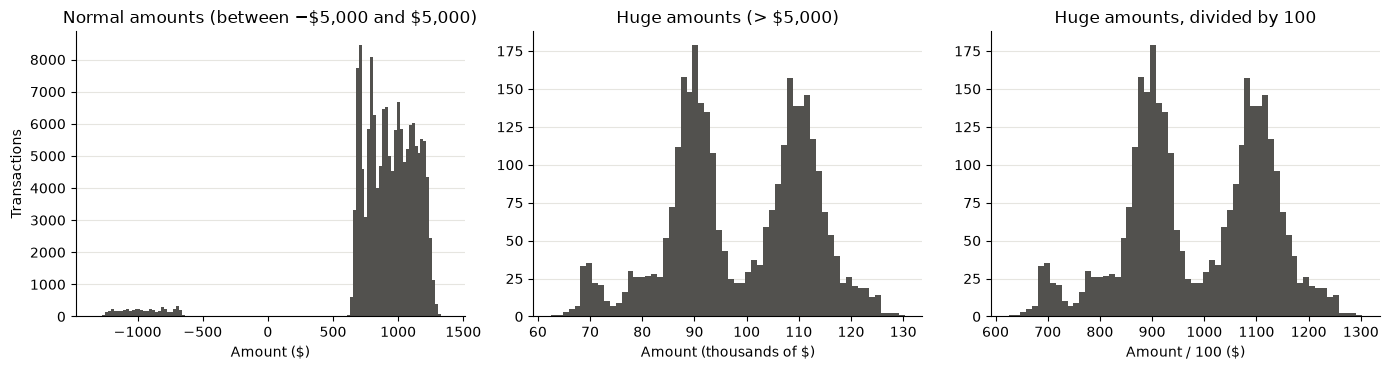

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(amount[~big], bins=120, color=GRAY)
axes[0].set_title(r"Normal amounts (between −\$5,000 and \$5,000)")
axes[0].set_xlabel(r"Amount (\$)")
axes[0].set_ylabel("Transactions")

axes[1].hist(amount[amount > 5_000] / 1_000, bins=60, color=GRAY)
axes[1].set_title(r"Huge amounts (> \$5,000)")
axes[1].set_xlabel(r"Amount (thousands of \$)")

axes[2].hist(amount[amount > 5_000] / 100, bins=60, color=GRAY)
axes[2].set_title("Huge amounts, divided by 100")
axes[2].set_xlabel(r"Amount / 100 (\$)")

for ax in axes: style_ax(ax)
plt.tight_layout(); plt.show()

In [7]:
# Typical price of each product (normal purchases only)
normal = tx[(amount > 0) & ~big]
normal.groupby("product")["amount"].agg(["count", "median", "min", "max"]).sort_values("median").style.format("{:,.0f}")

,count,median,min,max
product,,,,
Pixel,"25,306",699,599,798
Galaxy,"25,424",799,688,909
iPhone,"24,280",899,765,"1,017"
Pixel Pro,"25,009",999,845,"1,137"
iPhone Pro,"24,255","1,099",953,"1,259"
Galaxy Ultra,"25,204","1,199",992,"1,375"


The amounts form three groups:
- **Normal amounts**: each product has a stable price (Pixel ~\$699, Galaxy ~\$799, iPhone ~\$899, Pixel Pro ~\$999, iPhone Pro ~\$1,099, Galaxy Ultra ~\$1,199). The highest is \$1,375.
- **Negative amounts** (5,420 rows, 3.4%): the same order of magnitude as the prices. They are probably refunds or returns (examined at the end of section 3).
- **Huge amounts** (3,242 rows, 2.1%): from \$62,503 to \$130,284, which is impossible for a single phone. Divided by 100, they land exactly on the normal prices (right-hand chart). In my view, these are **amounts recorded in cents instead of dollars**. Two other clues point the same way: they are all whole numbers (like cents), and no amount lies between \$1,376 and \$62,503. They mostly affect **Apple** (~5% of its transactions, versus less than 1% for the others).

### 2.3 Duplicates

In [8]:
same_key = tx.duplicated(["user", "date", "product"], keep=False)
groups = tx[same_key].groupby(["user", "date", "product"])["amount"]

print(f"Rows copied identically                               : {tx.duplicated().sum()}")
print(f"Transactions repeating user + date + product          : {tx.duplicated(['user', 'date', 'product']).sum()}")
print(f"  groups where the amounts are identical              : {(groups.nunique() == 1).sum()}")
print(f"Transactions per user, on average                     : {len(tx) / tx['user'].nunique():.0f}")

Rows copied identically                               : 0
Transactions repeating user + date + product          : 837
  groups where the amounts are identical              : 0
Transactions per user, on average                     : 63


No row is copied identically. 837 transactions have the same user, date and product as another one, but their amounts are always different: they are not copies. With 2,500 people making 63 purchases on average over 3 years, a few purchases of the same product on the same day are plausible. **They are kept** (confirmed in section 4.3).

### 2.4 Panel composition and seasonality

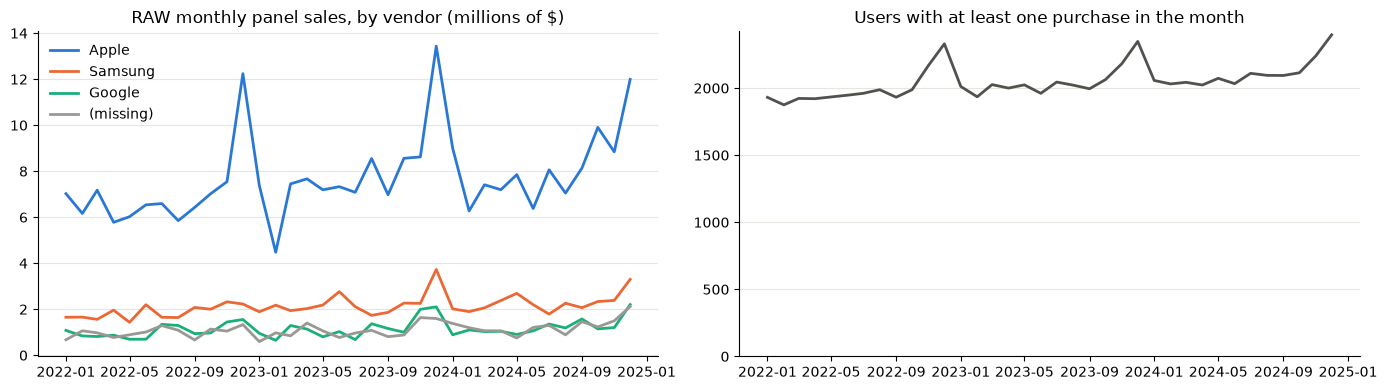

Quarter of each user's first purchase:
date
2022Q1    2460
2022Q2      39
2022Q3       1
Freq: Q-DEC



Active users in 2024-12: 2,397 out of 2,500


In [9]:
month = tx["date"].dt.to_period("M")
monthly = tx.groupby([month, tx["vendor"].fillna("(missing)")])["amount"].sum().unstack()
active_users = tx.groupby(month)["user"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for v in ["Apple", "Samsung", "Google", "(missing)"]:
    axes[0].plot(monthly.index.to_timestamp(), monthly[v] / 1e6, color=COLORS[v], linewidth=2, label=v)
axes[0].set_title(r"RAW monthly panel sales, by vendor (millions of \$)")
axes[0].legend(frameon=False)
axes[1].plot(active_users.index.to_timestamp(), active_users, color=GRAY, linewidth=2)
axes[1].set_title("Users with at least one purchase in the month")
axes[1].set_ylim(0, None)
for ax in axes: style_ax(ax)
plt.tight_layout(); plt.show()

first_seen = tx.groupby("user")["date"].min().dt.to_period("Q").value_counts().sort_index()
print("Quarter of each user's first purchase:")
print(first_seen.to_string())
print(f"\nActive users in {month.max()}: {active_users.iloc[-1]:,} out of {tx['user'].nunique():,}")

- **The panel is fixed**: 2,460 of the 2,500 people make their first purchase in the first quarter of 2022, the other 40 in the next two quarters, and 96% are still active in December 2024. Sales growth therefore comes from consumption, not from adding new people. No adjustment for panel size is needed.
- **Seasonality**: a peak every year in November–December (the holiday season). Reported revenue also has a much stronger Q4.
- **Apple's raw sales have isolated spikes**, caused by the amounts in cents.

### 2.5 Inspection summary

| Finding | Size | Decision | Checked in |
|---|---|---|---|
| Missing vendor | 15% of rows (36% of Pixel rows) | Infer the vendor from the product | 4.3 and 6.1 |
| Amounts in cents | 2.1% of rows (~5% at Apple) | Divide by 100 | 4.3 and 6.1 |
| Negative amounts | 3.4% of rows | Keep them: reported revenue is net | 4.3 and 6.1 |
| Apparent duplicates | 837 transactions | Keep them: different amounts | 4.3 and 6.1 |
| Holiday peak (Q4) | every year | The method must reproduce it | 4.1 |
| Fixed panel | 2,500 people | No adjustment needed | — |

## 3. Cleaning

Two corrections, and two kinds of rows kept as they are:
1. **Missing vendor → inferred from the product.** We also check that the rule is correct: on the 134,348 rows where the vendor is given, it always matches the product.
2. **Amounts in cents → divided by 100.** The \$5,000 threshold is safe: no amount lies between \$1,376 and \$62,503, so any threshold in that range gives the same result (checked in 6.1 with \$2,000 and \$10,000).
3. **Negative amounts → kept.** We assume reported revenue is net revenue, from which these amounts are subtracted (confirmed in section 4.3). Their exact nature is examined at the end of this section.
4. **Apparent duplicates → kept.** Their amounts are all different, so they are not copies (confirmed in section 4.3).

In [10]:
clean = tx.copy()

# Correction 1: vendor inferred from the product
clean["company"] = clean["product"].map(PRODUCT_TO_COMPANY)
known = clean["vendor"].notna()
assert (clean.loc[known, "vendor"] == clean.loc[known, "company"]).all()   # no contradiction

# Correction 2: amounts in cents divided by 100
in_cents = clean["amount"].abs() > 5_000
clean["amount_clean"] = np.where(in_cents, clean["amount"] / 100, clean["amount"])

print(f"Vendors inferred from the product : {(~known).sum():,}")
print(f"Amounts divided by 100            : {in_cents.sum():,}")
print(f"Amounts after cleaning            : from ${clean['amount_clean'].min():,.2f} to ${clean['amount_clean'].max():,.2f}")

Vendors inferred from the product : 23,683
Amounts divided by 100            : 3,242
Amounts after cleaning            : from $-1,339.94 to $1,375.20


In [11]:
# Total panel sales (3 years) at each cleaning step
steps = pd.DataFrame({
    "1. Raw": tx.groupby("vendor")["amount"].sum(),
    "2. + vendor inferred": clean.groupby("company")["amount"].sum(),
    "3. + cents fixed": clean.groupby("company")["amount_clean"].sum(),
}).reindex(COMPANIES) / 1e6
steps["Total change"] = steps["3. + cents fixed"] / steps["1. Raw"] - 1
steps.style.format("{:,.1f}", subset=steps.columns[:3]).format("{:+.0%}", subset=["Total change"]) \
    .set_caption("Total panel sales, 2022–2024 (USD millions)")

,1. Raw,2. + vendor inferred,3. + cents fixed,Total change
Apple,277.2,289.6,49.2,-82%
Samsung,76.7,80.0,49.1,-36%
Google,41.4,65.6,41.3,-0%


- **Apple: −82%.** The amounts in cents are only about 5% of its transactions, but each one counts 100 times: they made up more than four fifths of its raw sales.
- **Samsung: −36%.** Same problem, on a smaller scale.
- **Google: roughly 0%.** Two effects cancel out by chance: inferring the vendor adds 58%, then fixing the cents removes about as much.

Without cleaning, Apple would appear to sell 6.7 times more than Google. After cleaning, the three companies have comparable panel sales.

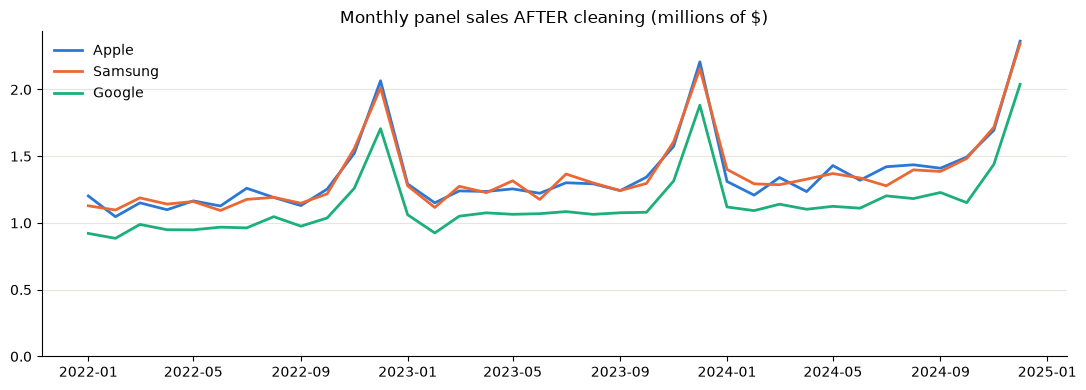

In [12]:
clean_monthly = clean.groupby([clean["date"].dt.to_period("M"), "company"])["amount_clean"].sum().unstack()

fig, ax = plt.subplots(figsize=(11, 4))
for c in COMPANIES:
    ax.plot(clean_monthly.index.to_timestamp(), clean_monthly[c] / 1e6, color=COLORS[c], linewidth=2, label=c)
ax.set_title(r"Monthly panel sales AFTER cleaning (millions of \$)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout(); plt.show()

After cleaning, the three curves are smooth: a holiday peak every year and slight growth.

Apple and Samsung have almost the same panel sales, while Apple's reported revenue is about 1.5 times Samsung's. The panel therefore does not represent each company in the same proportion. **Each company will need its own ratio.**

### Check: are the negative amounts returns?

A real return should follow a purchase of the same product by the same person, and refund the price paid. We check whether that is the case.

In [13]:
purchases = clean.loc[clean["amount_clean"] > 0, ["user", "product", "date", "amount_clean"]]

def earlier_purchases(rows):
    # Matches each row with earlier purchases of the same product by the same person
    m = rows.reset_index().merge(purchases, on=["user", "product"], suffixes=("", "_purchase"))
    return m[m["date_purchase"] < m["date"]]

def first_half_2022(dates):
    return (dates < "2022-07-01").sum()

refunds = clean[clean["amount_clean"] < 0]
random_buys = purchases.sample(len(refunds), random_state=0)   # comparison: ordinary purchases
m = earlier_purchases(refunds)
matched = refunds.index.isin(m["index"])
random_matched = random_buys.index.isin(earlier_purchases(random_buys)["index"])
same_amount = (m["amount_clean"].abs().round(2) == m["amount_clean_purchase"].round(2)).groupby(m["index"]).any()
min_delay = (m["date"] - m["date_purchase"]).dt.days.groupby(m["index"]).min()

print(f"{'':58}{'Negatives':>9}   {'Random purchases':>16}")
print(f"Preceded by a purchase of the same product, same person : {matched.mean():9.1%}   {random_matched.mean():16.1%}")
print(f"No earlier purchase                                     : {(~matched).sum():9d}   {(~random_matched).sum():16d}")
print(f"  of which in the first half of 2022                    : {first_half_2022(refunds.loc[~matched, 'date']):9d}   {first_half_2022(random_buys.loc[~random_matched, 'date']):16d}")
print(f"\nNegatives whose amount equals an earlier purchase : {same_amount.mean():.1%}")
print(f"Median delay since the most recent earlier purchase : {min_delay.median():.0f} days")

                                                          Negatives   Random purchases
Preceded by a purchase of the same product, same person :     90.5%              89.6%
No earlier purchase                                     :       515                561
  of which in the first half of 2022                    :       393                431

Negatives whose amount equals an earlier purchase : 0.1%
Median delay since the most recent earlier purchase : 69 days


**The test does not confirm that these are returns: the negative amounts behave like ordinary transactions.**
- They are preceded by a purchase of the same product by the same person almost as often as randomly drawn purchases (90.5% versus 89.6%). With 63 purchases per person on average, almost everyone has already bought every product: this match proves nothing.
- Those without an earlier purchase are concentrated at the start of the data (393 out of 515 in the first half of 2022), but so are randomly drawn purchases (431 out of 561): at the start of the data, nobody has a history yet. This pattern proves nothing either.
- Their amount almost never equals an earlier purchase (0.1%), whereas a real return would refund the price paid. The median delay since the most recent purchase is 69 days, which is long for a return; and it is a minimum, since the returned purchase could be older.

So we do not know exactly what these amounts represent. **The decision to keep them does not rely on this interpretation**, but on section 4.3: reported revenue is exactly proportional to panel sales only if they are kept.

## 4. Linking the panel to reported revenue

The basic idea is a **simple proportion**. If the panel always represents the same fraction of a company's sales, then:

$$\text{revenue} \approx \text{panel sales} \times \text{ratio}$$

So we need to check that the ratio is stable over time, and in particular that it changes neither with the seasons nor with growth. This section only uses the 10 reported quarters (2022Q1 to 2024Q2).

### 4.1 Is the ratio stable?

In [14]:
panel_q = panel_from(clean, "amount_clean", "company")   # cleaned panel sales, 12 quarters
ratio = revenue_q / panel_q.loc[TRAIN]                  # 10 reported quarters

view = ratio.copy()
view.index = view.index.astype(str)
view.style.format("{:,.0f}").set_caption("Ratio = reported revenue ÷ panel sales")

company,Apple,Samsung,Google
period,,,
2022Q1,"19,722","13,235","11,858"
2022Q2,"19,722","13,235","11,858"
2022Q3,"19,722","13,235","11,858"
2022Q4,"19,722","13,235","11,858"
2023Q1,"19,994","13,132","11,974"
2023Q2,"19,788","13,046","11,872"
2023Q3,"19,848","13,102","11,709"
2023Q4,"19,885","13,278","12,014"
2024Q1,"19,688","13,265","11,847"


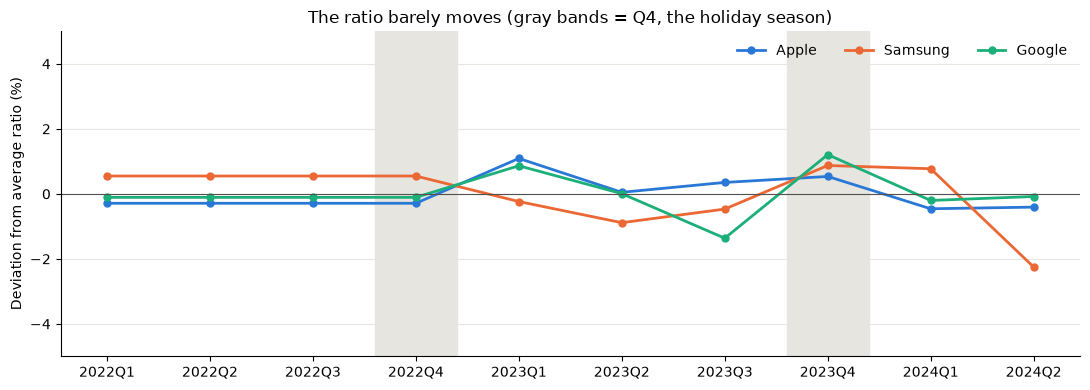

In [15]:
deviation = (ratio / ratio.mean() - 1) * 100   # deviation of each quarter from the average ratio, in %

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(TRAIN))
for xi in x[TRAIN.quarter == 4]:
    ax.axvspan(xi - 0.4, xi + 0.4, color="#e6e5e0", zorder=0)
for c in COMPANIES:
    ax.plot(x, deviation[c], color=COLORS[c], linewidth=2, marker="o", markersize=5, label=c)
ax.axhline(0, color=GRAY, linewidth=0.8)
ax.set_xticks(x, TRAIN.astype(str))
ax.set_ylim(-5, 5)
ax.set_ylabel("Deviation from average ratio (%)")
ax.set_title("The ratio barely moves (gray bands = Q4, the holiday season)")
ax.legend(frameon=False, ncol=3)
style_ax(ax)
plt.tight_layout(); plt.show()

In [16]:
t = np.arange(len(ratio))
stability = pd.DataFrame({
    "Average ratio": ratio.mean(),
    "Typical variation (%)": 100 * ratio.std() / ratio.mean(),
    "Largest deviation (%)": deviation.abs().max(),
    "Average deviation in Q4 (%)": deviation[TRAIN.quarter == 4].mean(),
    "Trend (% per year)": [100 * 4 * np.polyfit(t, ratio[c], 1)[0] / ratio[c].mean() for c in COMPANIES],
})
q3_to_q4 = 100 * panel_q.loc[TRAIN].pct_change()[TRAIN.quarter == 4]
print(f"For comparison, increase in panel sales from Q3 to Q4: from {q3_to_q4.min().min():.0f}% to {q3_to_q4.max().max():.0f}%")
stability.style.format("{:,.2f}").format("{:,.0f}", subset=["Average ratio"])

For comparison, increase in panel sales from Q3 to Q4: from 29% to 36%


,Average ratio,Typical variation (%),Largest deviation (%),Average deviation in Q4 (%),Trend (% per year)
company,,,,,
Apple,"19,779",0.51,1.09,0.12,0.07
Samsung,"13,163",0.98,2.25,0.71,-0.62
Google,"11,871",0.68,1.36,0.55,0.04


**The ratio is almost constant.** Its typical variation is below 1% and its largest deviation is 2.25% (Samsung, 2024Q2).
- **Negligible holiday effect**: in Q4, the ratio is only 0.1 to 0.7% above its average, while panel sales jump by 29 to 36% from Q3 to Q4. With only two Q4s in the data, a very small effect cannot be ruled out, but it would be irrelevant next to that jump.
- **Negligible trend**: less than 1% per year.

In other words, **seasonality and growth are already contained in panel sales**. The ratio only serves to go from the scale of the panel (a few million dollars) to the scale of the company (tens of billions).

The ratio is very different from one company to another (~19,800 for Apple, ~13,200 for Samsung, ~11,900 for Google): the panel under-represents Apple compared with the other two.

### 4.2 Does the panel follow year-over-year growth?

We compare each quarter with the same quarter of the previous year (for example 2023Q3 versus 2022Q3). This removes the seasonal effect and leaves only growth.

Largest gap between panel growth and revenue growth: 1.6 points


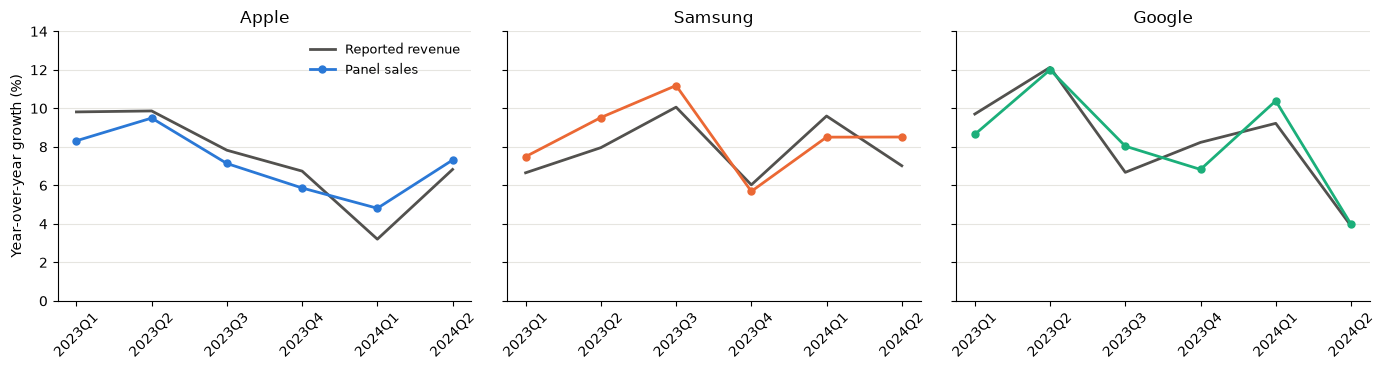

In [17]:
yoy_panel = 100 * panel_q.loc[TRAIN].pct_change(4)
yoy_revenue = 100 * revenue_q.pct_change(4)
print(f"Largest gap between panel growth and revenue growth: {(yoy_panel - yoy_revenue).abs().max().max():.1f} points")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
x = TRAIN[4:].astype(str)
for ax, c in zip(axes, COMPANIES):
    ax.plot(x, yoy_revenue[c].iloc[4:], color=GRAY, linewidth=2, label="Reported revenue")
    ax.plot(x, yoy_panel[c].iloc[4:], color=COLORS[c], linewidth=2, marker="o", markersize=5, label="Panel sales")
    ax.set_title(c)
    ax.tick_params(axis="x", labelrotation=45)
    style_ax(ax)
axes[0].set_ylim(0, 14)
axes[0].set_ylabel("Year-over-year growth (%)")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

Panel growth follows revenue growth to within 2 points. The panel therefore also captures the **trend**, not just the holiday peak. This is what justifies method B in section 5.

### 4.3 Checking the cleaning with 2022 data

In 2022, the ratio is **exactly** the same for all four quarters (variation of 0.0000% in the table below). Such a perfect equality cannot be a coincidence: the revenue in this exercise was most likely generated from the "true" panel sales, multiplied by a company-specific factor (with some noise from 2023 on).

This gives a very powerful test: **if one of my corrections were wrong, the equality would break.** So we remove each correction, one at a time, and measure the variation of the ratio in 2022. This test does not use any of the quarters to predict.

In [18]:
# Each variant removes ONE cleaning decision
variants = {
    "Chosen cleaning": panel_q,
    "Duplicates removed": panel_from(clean.drop_duplicates(["user", "date", "product"]), "amount_clean", "company"),
    "Negative amounts excluded": panel_from(clean[clean["amount_clean"] > 0], "amount_clean", "company"),
    "Vendor not inferred": panel_from(clean[clean["vendor"].notna()], "amount_clean", "vendor"),
    "Cents not fixed": panel_from(clean, "amount", "company"),
}
Y2022 = TRAIN[TRAIN.year == 2022]

def ratio_variation_2022(panel):
    """Typical variation (%) of the revenue / panel ratio over the 4 quarters of 2022."""
    r = revenue_q.loc[Y2022] / panel.loc[Y2022]
    return 100 * r.std() / r.mean()

pd.DataFrame({name: ratio_variation_2022(p) for name, p in variants.items()}).T \
    .style.format("{:.4f} %").set_caption("Variation of the ratio in 2022 (0 = perfect equality)")

company,Apple,Samsung,Google
Chosen cleaning,0.0000 %,0.0000 %,0.0000 %
Duplicates removed,0.1882 %,0.1422 %,0.1639 %
Negative amounts excluded,0.2557 %,0.4794 %,0.6369 %
Vendor not inferred,0.3143 %,0.3904 %,1.9641 %
Cents not fixed,4.8032 %,7.9313 %,11.6920 %


**Only the chosen cleaning gives a perfect equality** (zero variation). Removing any decision breaks it:
- **Cents not fixed**: 5 to 12% variation. This is by far the most serious error.
- **Vendor not inferred**: up to 2% for Google. Revenue therefore does include the transactions without a vendor.
- **Negative amounts excluded**: 0.3 to 0.6%. Revenue is indeed **net** of the negative amounts.
- **Duplicates removed**: 0.1 to 0.2%. They are indeed real purchases.

Each decision in section 3 is therefore confirmed **before** looking at the quarters to predict. With real data, we would never get such a perfect equality, but the idea is still useful: a correct cleaning should make the relationship between the panel and revenue more stable, which gives a way to check it.

## 5. Estimating revenue

### 5.1 Three methods

Each method is applied separately to each company. *T* is the quarter to estimate and *T − 4* the same quarter one year earlier.

| Method | Calculation | Idea |
|---|---|---|
| **A. Average ratio** | panel sales in *T* × average past ratio | The simple proportion from section 4.1 |
| **B. Last year × growth** | revenue in *T − 4* × (panel sales in *T* ÷ panel sales in *T − 4*) | The **holiday peak** comes from the same quarter last year; the **growth** comes from the panel (section 4.2) |
| C. No panel (benchmark) | revenue in *T − 4* × average past yearly growth (0% if there is no history yet) | Does **not** use the transactions. Measures what the panel adds |

**Chosen method: the average of A and B.** B is in fact the same as multiplying panel sales by the ratio of the same quarter last year, since revenue(*T − 4*) ÷ sales(*T − 4*) is that ratio. A and B therefore both assume the ratio is stable, but estimate it differently:
- **A** averages all past quarters: it is not very sensitive to the noise of a single quarter, but would react slowly if the ratio started to change;
- **B** only uses the same quarter last year: it would better follow a ratio that changes or varies with the season, but it depends on the noise of that single quarter.

Averaging them balances these two weaknesses.

In [19]:
MODELS = ["A. Average ratio", "B. Last year × growth", "C. No panel (benchmark)", "Final (average of A and B)"]

def predict(model, company, target, history, panel=None):
    """Estimates the revenue of `company` in quarter `target`, using only the revenue of quarters `history`.
    `panel` makes it possible to test another version of the data (section 6.1); by default, the cleaned panel."""
    panel = panel_q if panel is None else panel
    R, P = revenue_q[company], panel[company]
    last_year = target - 4
    if model == MODELS[0]:
        return P[target] * (R[history] / P[history]).mean()
    if model == MODELS[1]:
        return R[last_year] * P[target] / P[last_year]
    if model == MODELS[2]:
        yearly_growth = (R[history] / R[history].shift(4)).dropna()
        return R[last_year] * (yearly_growth.mean() if len(yearly_growth) else 1.0)
    if model == MODELS[3]:
        return (predict(MODELS[0], company, target, history, panel) + predict(MODELS[1], company, target, history, panel)) / 2
    raise ValueError(model)

### 5.2 Testing the methods on the past (backtest)

For each quarter from 2023Q1 to 2024Q2, we act as if we were just before it: we use **only the previous quarters** to estimate, then compare with the actual revenue. This gives 6 quarters × 3 companies = 18 tests per method. (2022 cannot be used as a test, because methods B and C need the previous year.)

In [20]:
rows = []
for i, target in enumerate(TRAIN):
    if i < 4:                 # at least one year of history is needed
        continue
    history = TRAIN[:i]       # only the previous quarters
    for company in COMPANIES:
        actual = revenue_q.loc[target, company]
        for model in MODELS:
            pred = predict(model, company, target, history)
            rows.append({"period": str(target), "company": company, "model": model,
                         "error (%)": 100 * (pred / actual - 1)})
backtest = pd.DataFrame(rows)

backtest["absolute error"] = backtest["error (%)"].abs()
backtest_table = backtest.pivot_table(index="model", columns="company", values="absolute error")[COMPANIES]
backtest_table["Average"] = backtest.groupby("model")["absolute error"].mean()
backtest_table["Bias"] = backtest.groupby("model")["error (%)"].mean()
backtest_table.loc[MODELS].style.format("{:.2f} %") \
    .set_caption("Backtest 2023Q1–2024Q2: average error (bias = average error keeping the sign)")

company,Apple,Samsung,Google,Average,Bias
model,,,,,
A. Average ratio,0.55 %,1.11 %,0.69 %,0.78 %,0.13 %
B. Last year × growth,0.86 %,1.00 %,0.80 %,0.89 %,0.12 %
C. No panel (benchmark),3.16 %,2.46 %,3.55 %,3.05 %,-0.47 %
Final (average of A and B),0.71 %,1.05 %,0.73 %,0.83 %,0.12 %


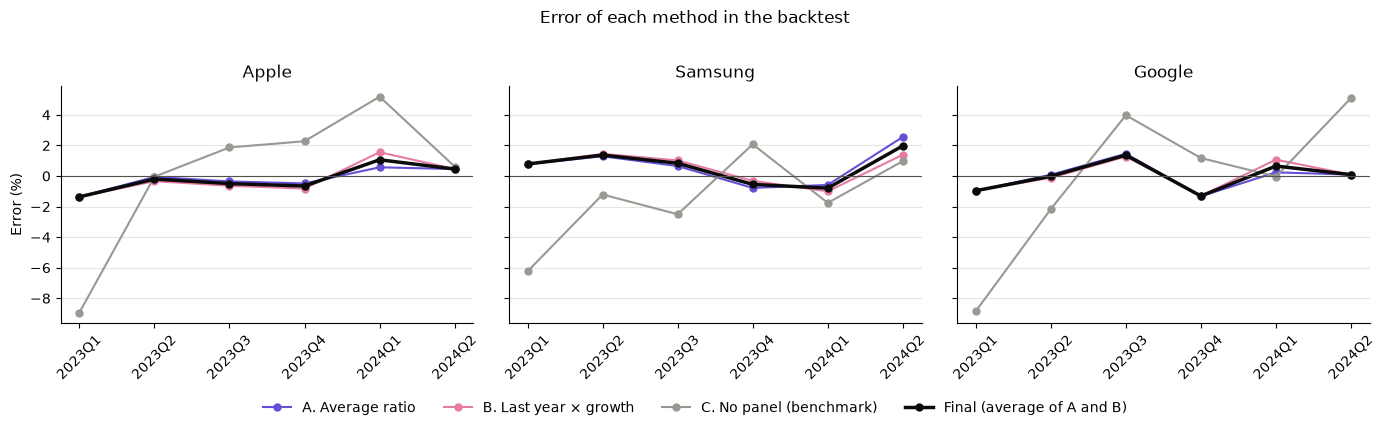

In [21]:
model_colors = {MODELS[0]: "#6250d6", MODELS[1]: "#e87ba4", MODELS[2]: "#9a9893", MODELS[3]: "#0b0b0b"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, company in zip(axes, COMPANIES):
    sub = backtest[backtest["company"] == company]
    for model in MODELS:
        s = sub[sub["model"] == model]
        ax.plot(s["period"], s["error (%)"], color=model_colors[model], marker="o", markersize=5,
                linewidth=2.5 if model == MODELS[3] else 1.5, label=model)
    ax.axhline(0, color=GRAY, linewidth=0.8)
    ax.set_title(company)
    ax.tick_params(axis="x", labelrotation=45)
    style_ax(ax)
axes[0].set_ylabel("Error (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Error of each method in the backtest", y=1.02)
plt.tight_layout(); plt.show()

- **A and B are off by less than 1% on average** (0.78% and 0.89%). **C**, which does not use the transactions, is off by 3.05%, almost 4 times more. The panel therefore provides real information: it measures each quarter's growth, whereas C assumes growth is always equal to the past average.
- A and B make very similar errors, because both multiply panel sales by a past ratio: when the panel deviates from revenue in a given quarter, both are wrong in the same direction.
- The average of A and B (0.83%) lies between the two.
- No bias: on average, there is neither overestimation nor underestimation (+0.1%).

### 5.3 Estimates for Q3 and Q4 2024

Each method is applied with the 10 reported quarters, then with the panel sales of Q3 and Q4 2024.

**Uncertainty interval:** we measure the standard error of the chosen method on the 18 backtest tests (square root of the mean squared error), then take ± 2 standard errors. If the errors are roughly normally distributed, this corresponds to about 95% confidence; with only 18 tests, it is an approximation.

In [22]:
forecast = pd.DataFrame([
    {"period": str(t), "company": c, "model": m, "forecast": predict(m, c, t, TRAIN)}
    for t in TEST_PERIODS for c in COMPANIES for m in MODELS
])
final_forecast = (forecast[forecast["model"] == MODELS[3]]
                  .pivot(index="period", columns="company", values="forecast")[COMPANIES])

final_errors = backtest.loc[backtest["model"] == MODELS[3], "error (%)"] / 100
RMSE = np.sqrt((final_errors ** 2).mean())
print(f"Standard error in the backtest: {RMSE:.2%}  ->  interval of ± {2 * RMSE:.2%}")

est = final_forecast.stack()
final_table = pd.DataFrame({
    "Low (USD bn)": est / (1 + 2 * RMSE) / 1e9,      # error = estimate / actual − 1, so actual = estimate / (1 + error)
    "Estimate (USD bn)": est / 1e9,
    "High (USD bn)": est / (1 - 2 * RMSE) / 1e9,
}).swaplevel().sort_index().reindex(COMPANIES, level=0)
final_table.style.format("{:,.2f}").set_caption("Estimated revenue for Q3–Q4 2024 (USD billions)")

Standard error in the backtest: 0.97%  ->  interval of ± 1.94%


## 6. Comparison with actual Q3–Q4 2024 revenue

The estimates from section 5.3 are now frozen. We load the full file, which contains the actual Q3–Q4 2024 revenue, for the first time.

In [23]:
EVAL_AVAILABLE = os.path.exists(ACTUALS_PATH)

if EVAL_AVAILABLE:
    actuals = pd.read_csv(ACTUALS_PATH)
    actuals["period"] = quarter_period(actuals)
    revenue_full = actuals.pivot(index="period", columns="company", values="revenue")[COMPANIES]
    # Check: the full file must be identical to the masked file on the 10 common quarters
    assert np.allclose(revenue_full.loc[TRAIN], revenue_q.loc[TRAIN])
    print(f"Full file loaded: from {revenue_full.index.min()} to {revenue_full.index.max()}, identical to the masked file on {len(TRAIN)} quarters")
else:
    print(f"File {ACTUALS_PATH} not found: section 6 is skipped. The estimates from section 5.3 remain valid.")

Full file loaded: from 2022Q1 to 2024Q4, identical to the masked file on 10 quarters


In [24]:
if EVAL_AVAILABLE:
    actual_test = revenue_full.loc[TEST_PERIODS, COMPANIES]
    actual_test.index = actual_test.index.astype(str)

    final_eval = final_table.copy()
    final_eval["Actual (USD bn)"] = actual_test.stack().swaplevel() / 1e9
    final_eval["Error (%)"] = 100 * (final_eval["Estimate (USD bn)"] / final_eval["Actual (USD bn)"] - 1)
    final_eval["In interval"] = final_eval["Actual (USD bn)"].between(final_eval["Low (USD bn)"], final_eval["High (USD bn)"]).map({True: "yes", False: "no"})
    display(final_eval.style
            .format("{:,.2f}", subset=["Low (USD bn)", "Estimate (USD bn)", "High (USD bn)", "Actual (USD bn)"])
            .format("{:+.2f} %", subset=["Error (%)"])
            .set_caption("Chosen method: estimate vs actual"))

In [25]:
if EVAL_AVAILABLE:
    forecast["actual"] = [revenue_full.loc[pd.Period(p), c] for p, c in zip(forecast["period"], forecast["company"])]
    forecast["absolute error"] = 100 * (forecast["forecast"] / forecast["actual"] - 1).abs()
    comparison = pd.DataFrame({
        "Average error, backtest": backtest_table["Average"],
        "Average error, Q3–Q4 2024": forecast.groupby("model")["absolute error"].mean(),
        "Worst error, Q3–Q4 2024": forecast.groupby("model")["absolute error"].max(),
    }).loc[MODELS]
    display(comparison.style.format("{:.2f} %").set_caption("All methods: backtest vs actual quarters"))

,"Average error, backtest","Average error, Q3–Q4 2024","Worst error, Q3–Q4 2024"
model,,,
A. Average ratio,0.78 %,0.68 %,1.21 %
B. Last year × growth,0.89 %,0.46 %,1.25 %
C. No panel (benchmark),3.05 %,2.47 %,4.15 %
Final (average of A and B),0.83 %,0.54 %,0.72 %


- **Average error of 0.54%, worst error of 0.72%.** This is the right order of magnitude, and even slightly better than in the backtest (0.83%): the method works on quarters it had never seen.
- **All 6 actual revenues fall within the interval** of ± 1.94%, with a wide margin.
- Here, B (0.46%) does better than A (0.68%), the opposite of the backtest: the gap between the two is probably due to chance. The average has the smallest **worst** error (0.72%, versus about 1.2% for A and B). That is the point of not betting everything on a single method.
- The method without the panel (C) is off by 2.47% on average, about 4.5 times more.
- No clear bias: Q3 is slightly overestimated for all three companies (+0.34 to +0.54%), but three errors with the same sign happen one time in four by pure chance, and in Q4 the errors go both ways (Apple and Samsung underestimated, Google overestimated).

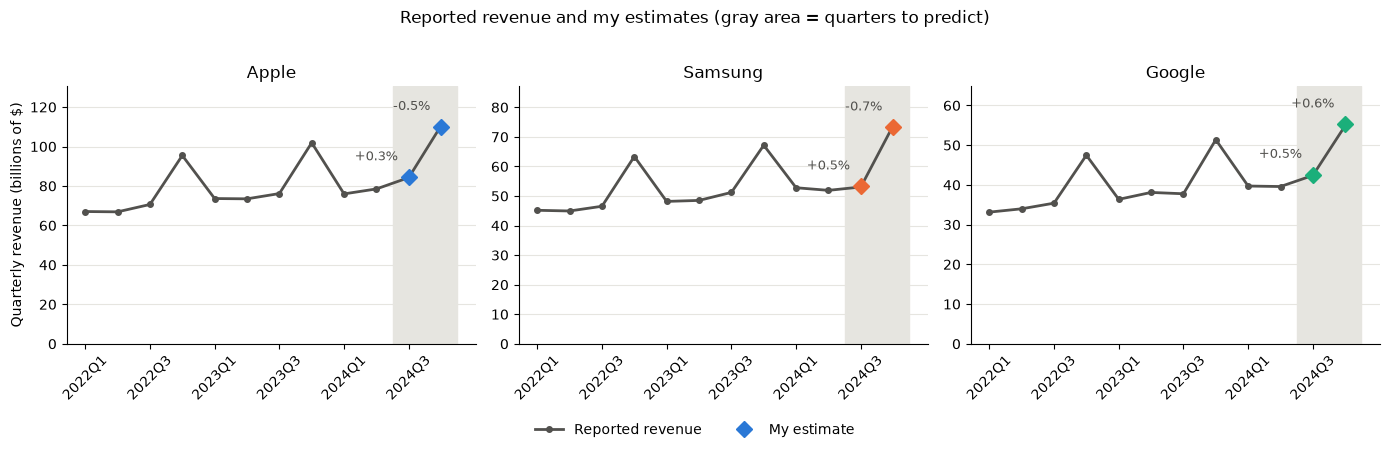

In [26]:
if EVAL_AVAILABLE:
    x_all = list(revenue_full.index.astype(str))
    test_pos = [x_all.index(str(p)) for p in TEST_PERIODS]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, company in zip(axes, COMPANIES):
        ax.plot(x_all, revenue_full[company] / 1e9, color=GRAY, linewidth=2, marker="o", markersize=4, label="Reported revenue")
        est_c = final_forecast[company] / 1e9
        ax.plot(est_c.index, est_c.values, color=COLORS[company], linestyle="none", marker="D", markersize=8, label="My estimate")
        for p, v in est_c.items():
            ax.annotate(f"{final_eval.loc[(company, p), 'Error (%)']:+.1f}%", (p, v), textcoords="offset points",
                        xytext=(-8, 12), ha="right", fontsize=9, color=GRAY)
        ax.axvspan(min(test_pos) - 0.5, max(test_pos) + 0.5, color="#e6e5e0", zorder=0)
        ax.set_title(company)
        ax.set_ylim(0, revenue_full[company].max() / 1e9 * 1.18)
        ax.set_xticks(range(0, len(x_all), 2), x_all[::2])
        ax.tick_params(axis="x", labelrotation=45)
        style_ax(ax)
    axes[0].set_ylabel(r"Quarterly revenue (billions of \$)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.08))
    fig.suptitle("Reported revenue and my estimates (gray area = quarters to predict)", y=1.02)
    plt.tight_layout(); plt.show()

### 6.1 What if other choices had been made?

We redo exactly the same Q3–Q4 2024 estimate, changing **only one** cleaning decision at a time. This shows how much each decision matters.

In [27]:
def evaluate(panel):
    """Error (%) of the chosen method on Q3–Q4 2024, for a given version of the panel."""
    return pd.Series({
        (c, str(t)): 100 * (predict(MODELS[3], c, t, TRAIN, panel) / revenue_full.loc[t, c] - 1)
        for c in COMPANIES for t in TEST_PERIODS
    })

if EVAL_AVAILABLE:
    scenarios = {
        "Chosen cleaning": panel_q,
        "Cents not fixed": variants["Cents not fixed"],
        "Vendor not inferred": variants["Vendor not inferred"],
        "Negative amounts excluded": variants["Negative amounts excluded"],
        "Duplicates removed": variants["Duplicates removed"],
        "No correction (raw data)": panel_from(tx.dropna(subset=["vendor"]), "amount", "vendor"),
    }
    for threshold in [2_000, 10_000]:
        amount_alt = np.where(clean["amount"].abs() > threshold, clean["amount"] / 100, clean["amount"])
        scenarios[f"Cents threshold at {threshold:,} USD"] = panel_from(clean.assign(amount_alt=amount_alt), "amount_alt", "company")

    errors = pd.DataFrame({name: evaluate(p) for name, p in scenarios.items()}).T.abs()
    scenario_table = errors.T.groupby(level=0).mean().T[COMPANIES]
    scenario_table["Average"] = errors.mean(axis=1)
    scenario_table["Worst error"] = errors.max(axis=1)
    display(scenario_table.style.format("{:.2f} %").set_caption("Average error on Q3–Q4 2024 depending on cleaning choices"))

,Apple,Samsung,Google,Average,Worst error
Chosen cleaning,0.42 %,0.63 %,0.58 %,0.54 %,0.72 %
Cents not fixed,3.12 %,6.30 %,12.12 %,7.18 %,14.53 %
Vendor not inferred,0.77 %,0.63 %,0.93 %,0.78 %,1.76 %
Negative amounts excluded,0.30 %,0.94 %,1.16 %,0.80 %,1.77 %
Duplicates removed,0.48 %,0.63 %,0.47 %,0.53 %,0.74 %
No correction (raw data),5.09 %,5.18 %,12.13 %,7.47 %,16.73 %
"Cents threshold at 2,000 USD",0.42 %,0.63 %,0.58 %,0.54 %,0.72 %
"Cents threshold at 10,000 USD",0.42 %,0.63 %,0.58 %,0.54 %,0.72 %


- **Fixing the cents is essential**: without this correction, the error goes from 0.54% to 7.18%. These amounts inflate each quarter by a different amount, and the ratio cannot compensate for noise that keeps changing.
- **Inferring the vendor helps, but less than one might think** (0.78% without, versus 0.54% with). Google loses about the same third of its Pixel rows every quarter; this gap is stable, so Google's ratio largely compensates for it. **Lesson: a stable bias is absorbed by the ratio, a changing noise is not.**
- **Excluding the negative amounts** makes the error worse (0.80%), which confirms section 4.3.
- **Removing duplicates or changing the cents threshold** barely changes anything here. For duplicates, it is the test in section 4.3 that settles the question.

## 7. Assumptions and their effect on the results

The assignment asks to document the assumptions and explain how they affect the results. The table brings them together. The last column comes from section 6.1: average error on Q3–Q4 2024 if the assumption were dropped (versus 0.54% with all assumptions).

| # | Assumption | Why we believe it | Error if dropped |
|---|---|---|---|
| 1 | Amounts above \$5,000 are in cents | Impossible in dollars; divided by 100 they land on normal prices; they are all whole numbers; perfect equality in 2022 (4.3) | 7.18% |
| 2 | The missing vendor can be inferred from the product | No product has two vendors (2.1); perfect equality in 2022 (4.3) | 0.78% |
| 3 | Negative amounts are part of net revenue | Perfect equality in 2022 only if they are kept (4.3), even though we cannot confirm they are returns (end of section 3) | 0.80% |
| 4 | Apparent duplicates are real purchases | All amounts are different (2.3); perfect equality in 2022 (4.3) | 0.53% (negligible effect) |
| 5 | The \$5,000 threshold separates the two groups well | No amount between \$1,376 and \$62,503 (2.2) | 0.54% (no effect) |
| 6 | Each company's ratio stays stable over time | Typical variation below 1%, negligible holiday effect and trend (4.1); panel growth follows revenue growth (4.2) | Not measurable here. If the ratio started to drift (for example because the panel's composition changes), all estimates would be off; B, which uses last year's ratio, would adjust faster than A |

## 8. Limitations

- **The panel is small.** About 4,400 transactions per company per quarter must represent tens of billions of dollars: a single phone bought in the panel is "worth" 8 to 24 million dollars of revenue. With a real panel, drawn at random from the population, this alone would create an error of about 1.5% per quarter (1/√4,400). My errors are smaller because here, revenue was most likely generated from the panel itself (section 4.3). **On real data, an error of 2 to 5% would already be a good result.**
- **The panel does not represent the market.** The ratios differ a lot between companies, perhaps because of a geographic, age or card-issuer bias. The method works as long as this bias stays stable; it would fail if the panel's composition changed.
- **Reported revenue does not come only from phones paid by card.** It also includes services, other devices and sales to carriers. We assume all of this evolves at the same pace as the panel.
- **Only 10 quarters of history**, so statistical tests have little power.

## 9. Conclusion

Credit card transactions make it possible to estimate the quarterly revenue of the three companies **to within about 0.5%**, provided the data is cleaned. The three traps (amounts in cents, missing vendor, negative amounts) were found during inspection, handled, then **confirmed with the 2022 data**, before looking at the quarters to predict. A simple proportion, combined with the revenue of the same quarter last year, is then enough, because panel sales already contain the holiday peak and the growth.

In [28]:
if EVAL_AVAILABLE:
    display(final_eval[["Low (USD bn)", "Estimate (USD bn)", "High (USD bn)", "Actual (USD bn)", "Error (%)"]].style
            .format("{:,.2f}", subset=["Low (USD bn)", "Estimate (USD bn)", "High (USD bn)", "Actual (USD bn)"])
            .format("{:+.2f} %", subset=["Error (%)"])
            .set_caption(f"Final result — average error: {final_eval['Error (%)'].abs().mean():.2f} %"))
else:
    display(final_table.style.format("{:,.2f}").set_caption("Estimated revenue for Q3–Q4 2024 (USD billions)"))